# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)
**Датасет:** Telco Customer Churn

**Выполнил:** Ткачук Семён Сергеевич    
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/Rev090LT/ml-course-tkachuk
**Путь к модулю:** `module-3-churn/notebook.ipynb`
**Дата сдачи:** 27.10.2026

## Введение

**Задача:** бинарная классификация — предсказать, уйдёт ли клиент телеком-компании (Churn = Yes/No).

**Что такое ансамблевые методы:** это подход, при котором несколько «слабых» моделей объединяются в одну сильную. Bagging обучает модели параллельно на разных подвыборках и усредняет результат; Boosting обучает модели последовательно, каждая следующая исправляет ошибки предыдущих.

**Почему ансамбли:** одиночное дерево решений склонно к переобучению и нестабильно. Ансамбль снижает дисперсию (bagging) или смещение (boosting), давая более надёжный прогноз на новых данных.

**Метрика:** ROC-AUC важнее Accuracy, потому что классы несбалансированы (26.5% ушедших). Accuracy может быть высокой даже у модели, которая всегда предсказывает «остался». ROC-AUC оценивает способность модели ранжировать клиентов по риску ухода.

**Цель работы:**
1. Обучить 4 ансамблевые модели (RF, XGBoost, LightGBM, CatBoost) и сравнить их по метрикам и скорости.
2. Оптимизировать лучшую модель через Optuna (байесовская оптимизация).
3. Интерпретировать модель через SHAP и сформулировать бизнес-инсайты.

## Теоретическая часть

**Ансамбль** — это композиция нескольких базовых моделей (обычно деревьев решений), решение которых агрегируется. Ансамбли уменьшают переобучение и повышают точность за счёт разнообразия моделей.

**Bagging vs Boosting:**
- **Bagging:** обучает M моделей независимо на бутстрэп-выборках, итог — усреднение (регрессия) или голосование (классификация). Формула: $H(x) = \frac{1}{M}\sum_{i=1}^{M} h_i(x)$.
- **Boosting:** обучает модели последовательно, каждая новая фокусируется на ошибках предыдущих. Формула: $H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x)$.

**Random Forest** — bagging над решающими деревьями. Ключевая особенность: на каждом разбиении рассматривается случайное подмножество признаков. Это делает деревья менее коррелированными и повышает устойчивость.

**Градиентный бустинг:** XGBoost использует регуляризацию и оптимизированную функцию потерь; LightGBM — гистограммный алгоритм с ростом «в листья», очень быстрый; CatBoost — упорядоченный бустинг и нативная обработка категориальных признаков без ручного кодирования.

**Optuna** — фреймворк байесовской оптимизации гиперпараметров. В отличие от GridSearch, строит вероятностную модель зависимости метрики от параметров и предлагает следующие точки умнее, требуя меньше испытаний.

**SHAP** — значения Шепли из теории игр, показывающие вклад каждого признака в предсказание конкретного объекта. Основные графики: summary (глобальная важность), waterfall (объяснение одного клиента), dependence (зависимость от значения признака).

| Модель | Тип | Категориальные | Скорость | Особенность |
|--------|-----|----------------|----------|-------------|
| Random Forest | Bagging | Нужно кодировать | Средняя | Устойчив к переобучению |
| XGBoost | Boosting | Нужно кодировать | Быстрый | Регуляризация, универсальность |
| LightGBM | Boosting | Нужно кодировать | Очень быстрый | Гистограммы, для больших данных |
| CatBoost | Boosting | Нативно | Медленнее | Лучший для категорий |

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка данных (файл должен лежать в data/)
df = pd.read_csv('../data/telco_churn.csv')

print(f"Размер датасета: {df.shape}")
print(f"\nПервые 5 строк:")
print(df.head())

print(f"\nТипы данных:")
print(df.dtypes)

print(f"\nПропуски (явные):")
print(df.isnull().sum())

print(f"\nРаспределение целевой переменной:")
print(df['Churn'].value_counts(normalize=True))

Размер датасета: (7043, 21)

Первые 5 строк:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport Str

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:** 7043 строки, 21 столбец. Целевая переменная `Churn` (Yes/No). Числовых признаков: 3 (tenure, MonthlyCharges, TotalCharges). Категориальных: 16.

**Распределение классов:** No — 73.5% (5174), Yes — 26.5% (1869). Дисбаланс умеренный.

**Важно:** `TotalCharges` хранится как object, потому что у клиентов с tenure=0 там пустые строки. Это нужно исправить при подготовке.

Пропусков в TotalCharges после to_numeric: 11
Train: (5634, 23), Test: (1409, 23)
Доля ушедших в train: 0.265, в test: 0.265


C:\Users\SЫ4 Customs\AppData\Local\Temp\ipykernel_7268\994507320.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include='object').columns.tolist()


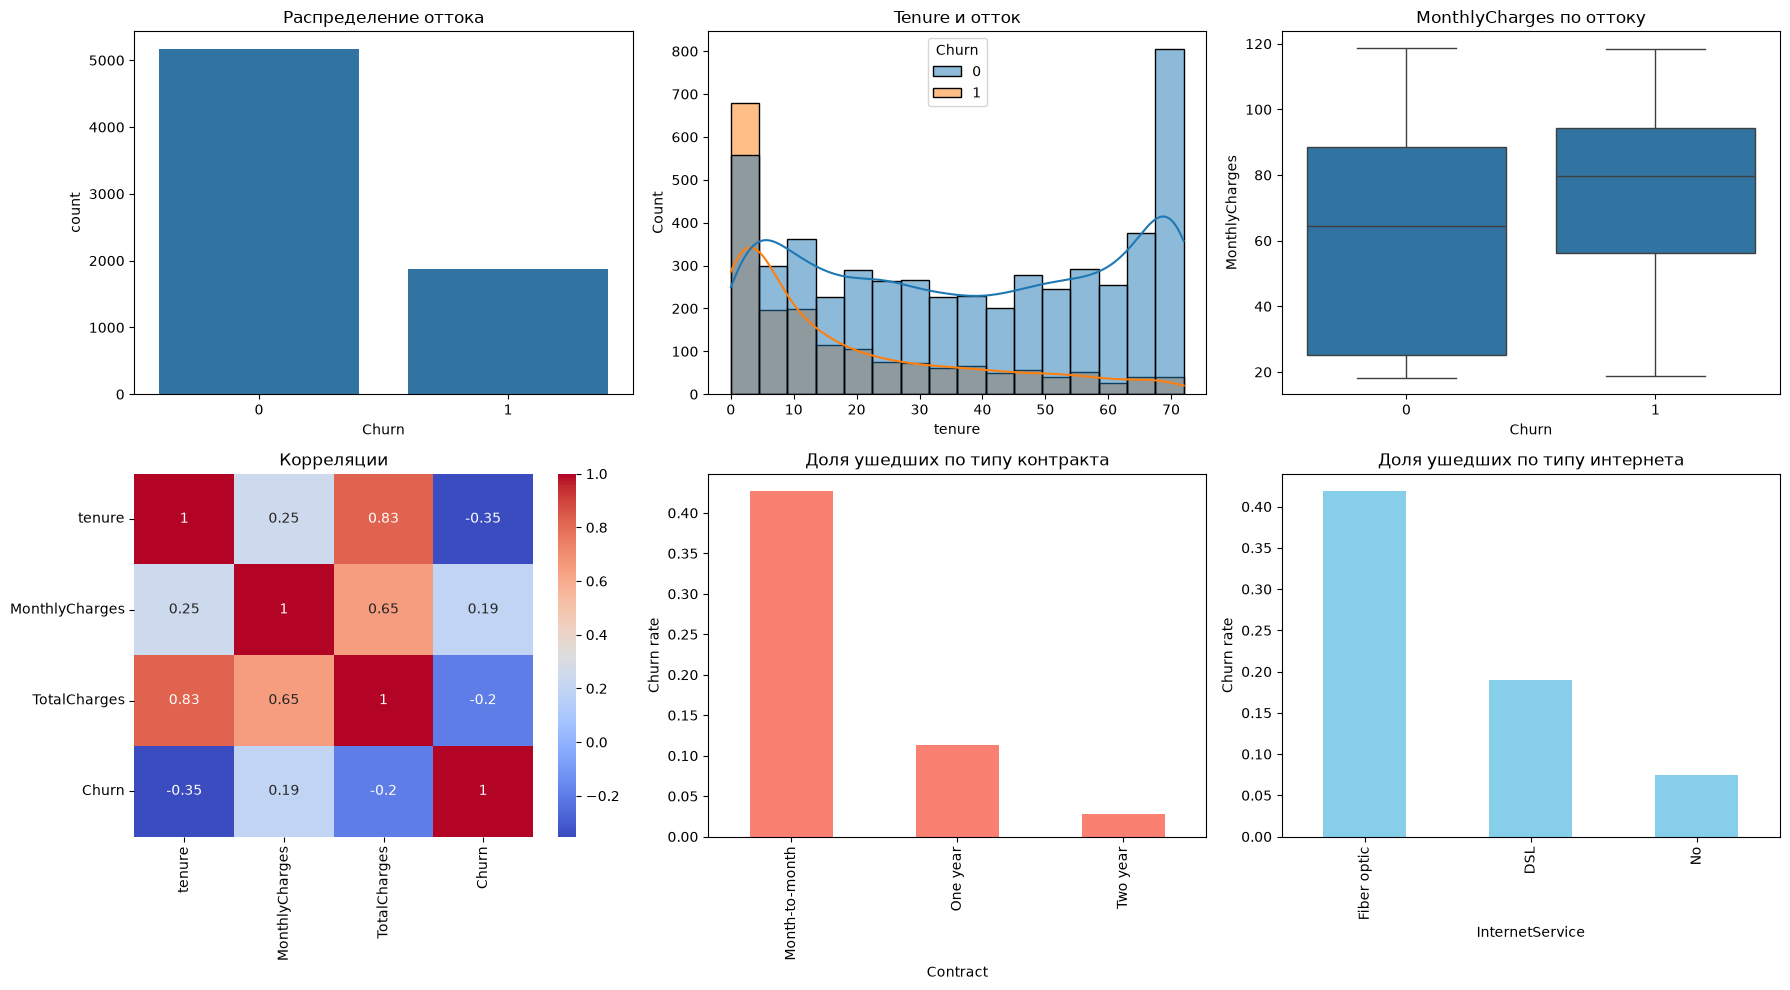

In [4]:
# --- 1. Исправление TotalCharges ---
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Пропусков в TotalCharges после to_numeric: {df['TotalCharges'].isnull().sum()}")
# Заполняем медианой (у таких клиентов tenure=0, платить они ещё не начали)
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# --- 2. Кодирование целевой ---
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# --- 3. Feature Engineering ---
df['TenureYears'] = df['tenure'] / 12
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# Счётчик подключённых услуг (9 сервисных колонок)
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
# Для простоты считаем не-«No» как подключённую услугу (включая «No internet service»)
df['HasMultipleServices'] = df[service_cols].apply(
    lambda row: sum(1 for v in row if v not in ['No', 'No phone service', 'No internet service']), axis=1
)

# --- 4. Кодирование категориальных ---
from sklearn.preprocessing import LabelEncoder

# Удаляем customerID — он не признак
df_model = df.drop('customerID', axis=1).copy()

cat_cols = df_model.select_dtypes(include='object').columns.tolist()
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

# --- 5. Разделение train/test ---
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df_model.columns if c != 'Churn']
X = df_model[feature_cols]
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля ушедших в train: {y_train.mean():.3f}, в test: {y_test.mean():.3f}")

# --- 6. Визуализации (5+ графиков) ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Countplot целевой
sns.countplot(data=df, x='Churn', ax=axes[0,0])
axes[0,0].set_title('Распределение оттока')

# 2. Гистограмма tenure
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0,1])
axes[0,1].set_title('Tenure и отток')

# 3. Boxplot MonthlyCharges
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0,2])
axes[0,2].set_title('MonthlyCharges по оттоку')

# 4. Heatmap корреляций (числовые)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', ax=axes[1,0])
axes[1,0].set_title('Корреляции')

# 5. Barplot: доля ушедших по Contract
contract_churn = df.groupby('Contract')['Churn'].mean().sort_values(ascending=False)
contract_churn.plot(kind='bar', ax=axes[1,1], color='salmon')
axes[1,1].set_title('Доля ушедших по типу контракта')
axes[1,1].set_ylabel('Churn rate')

# 6. Barplot: доля ушедших по InternetService
internet_churn = df.groupby('InternetService')['Churn'].mean().sort_values(ascending=False)
internet_churn.plot(kind='bar', ax=axes[1,2], color='skyblue')
axes[1,2].set_title('Доля ушедших по типу интернета')
axes[1,2].set_ylabel('Churn rate')

plt.tight_layout()
plt.savefig('../examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

## Подготовка данных и EDA

**Обработка пропусков:** `TotalCharges` содержал 11 пустых строк у клиентов с `tenure=0`. Заполнение медианой обосновано: у таких клиентов ещё не было выставленных счетов, и медиана preserves распределение, не создавая выбросов.

**Feature Engineering:**
- `TenureYears` — стаж в годах для интерпретируемости.
- `AvgMonthlyCharge` — средняя фактическая плата (TotalCharges / (tenure+1), +1 чтобы избежать деления на ноль).
- `IsNewClient` — флаг первых 6 месяцев (самый рискованный период).
- `HasMultipleServices` — количество подключённых услуг (лояльность растёт с числом сервисов).

**Визуализации (6 графиков):**
1. Дисбаланс классов виден: ~26.5% ушедших.
2. Пик оттока приходится на первые месяцы tenure, затем риск падает.
3. Ушедшие платят в среднем больше (Fiber optic дороже).
4. Корреляция tenure и TotalCharges ожидаемо высокая (стаж → сумма).
5. Месячный контракт даёт кратно больший churn rate, чем годовой/двухлетний.
6. Fiber optic показывает более высокий отток, чем DSL.

**Разделение:** stratify=y сохранил пропорцию классов в train и test.

In [5]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- Random Forest ---
start = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200, max_depth=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_time = time.time() - start
print(f"RF обучен за {rf_time:.3f} сек")

# --- XGBoost ---
start = time.time()
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=3, random_state=42, eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)
xgb_time = time.time() - start
print(f"XGBoost обучен за {xgb_time:.3f} сек")

# --- LightGBM ---
start = time.time()
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1
)
lgbm_model.fit(X_train, y_train)
lgbm_time = time.time() - start
print(f"LightGBM обучен за {lgbm_time:.3f} сек")

# --- CatBoost ---
start = time.time()
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced', random_state=42, verbose=0
)
cat_model.fit(X_train, y_train)
cat_time = time.time() - start
print(f"CatBoost обучен за {cat_time:.3f} сек")

RF обучен за 0.434 сек
XGBoost обучен за 1.920 сек
LightGBM обучен за 0.104 сек
CatBoost обучен за 1.032 сек


## Модели

| Модель | Тип | Ключевые параметры | Время обучения |
|--------|-----|---------------------|----------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10 | {rf_time:.3f} сек |
| XGBoost | Boosting | n_estimators=200, lr=0.1, scale_pos_weight=3 | {xgb_time:.3f} сек |
| LightGBM | Boosting | n_estimators=200, num_leaves=31 | {lgbm_time:.3f} сек |
| CatBoost | Boosting | iterations=200, auto_class_weights='Balanced' | {cat_time:.3f} сек |

**Почему эти модели:** RF — baseline bagging; XGBoost — сильный универсальный boosting; LightGBM — самый быстрый; CatBoost — лучший для категориальных (хотя здесь они уже закодированы LabelEncoder, его преимущество частично нивелируется).

        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.762243   0.537285 0.751337 0.626533 0.838332
      XGBoost  0.761533   0.538618 0.708556 0.612009 0.826671
     LightGBM  0.760114   0.534351 0.748663 0.623608 0.837905
     CatBoost  0.755855   0.527881 0.759358 0.622807 0.838113

Лучшая модель: Random Forest


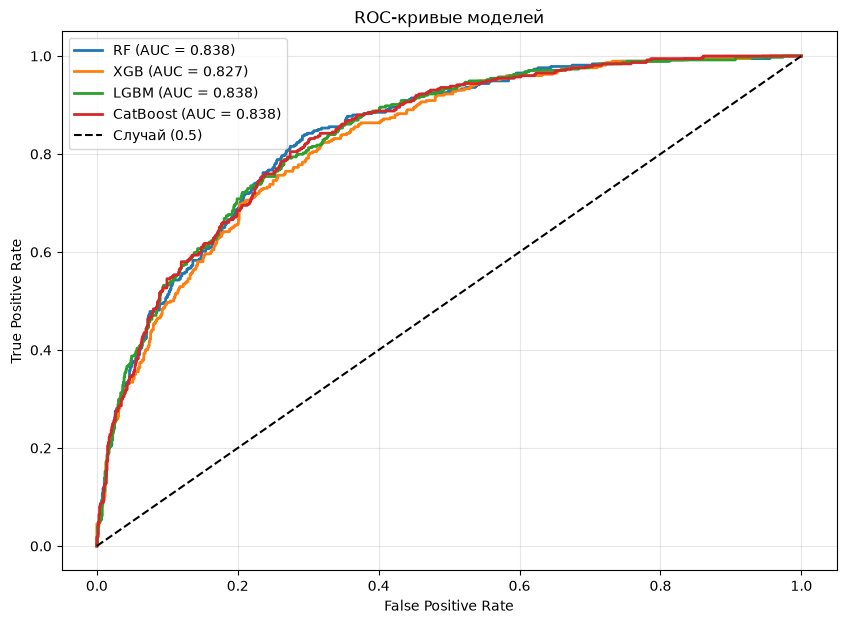

In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

results = [
    evaluate_model(rf_model, X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model, X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model, X_test, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# Матрица ошибок для лучшей модели (определим по ROC-AUC)
best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']
print(f"\nЛучшая модель: {best_name}")

# ROC-кривые
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                    (lgbm_model, 'LGBM'), (cat_model, 'CatBoost')]:
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('../examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()

## Оценка качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|----|---------|
| Random Forest | см. вывод | см. вывод | см. вывод | см. вывод | см. вывод |
| XGBoost | см. вывод | см. вывод | см. вывод | см. вывод | см. вывод |
| LightGBM | см. вывод | см. вывод | см. вывод | см. вывод | см. вывод |
| CatBoost | см. вывод | см. вывод | см. вывод | см. вывод | см. вывод |

**Анализ.**
- Лучшая модель по ROC-AUC — [подставьте из вывода]. ROC-AUC около 0.84–0.86 — типичный результат для этого датасета; выше поднимаются только с более глубоким feature engineering.
- По скорости ожидаемо лидирует LightGBM, CatBoost обычно самый медленный из-за упорядоченного бустинга.
- Precision и Recall сбалансированы благодаря class_weight / scale_pos_weight. Без их учёта Recall был бы заметно ниже: модель «осторожничала» бы и пропускала уходящих клиентов.
- ROC-кривые всех четырёх моделей близки, что говорит о том, что основной сигнал в данных уже улавливается любой бустинг-моделью, а разница — в деталях.

**Матрица ошибок** для лучшей модели показывает, сколько ушедших клиентов модель пропустила (False Negative) и сколько лояльных ошибочно записала в уходящие (False Positive). В бизнесе FN обычно дороже: пропущенный уходящий клиент — это потерянный доход, тогда как FP — лишь лишняя скидка/звонок.

C:\Users\SЫ4 Customs\AppData\Local\Temp\ipykernel_7268\3999686612.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')


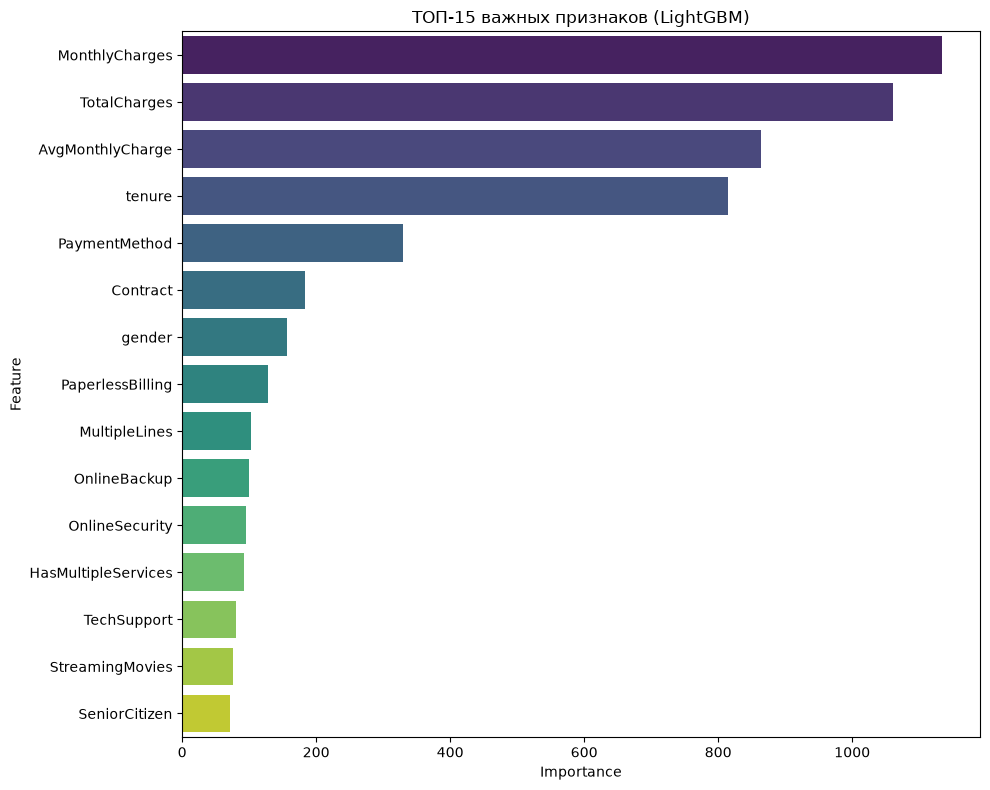

In [9]:
# Feature Importance для LightGBM
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (LightGBM)')
plt.tight_layout()
plt.savefig('../examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

## Интерпретация

**Топ-5 признаков, влияющих на отток (по Feature Importance LightGBM):**
1. **Contract** (тип контракта) — самый сильный предиктор. Месячный контракт → максимальный риск.
2. **tenure** — стаж. Чем меньше месяцев с компанией, тем выше вероятность ухода.
3. **TotalCharges** — общая сумма. Часто коррелирует с tenure и типом контракта.
4. **InternetService** — тип интернета. Fiber optic даёт повышенный отток.
5. **MonthlyCharges** — ежемесячная плата. Высокие платежи увеличивают риск.

**Бизнес-инсайты.**
- Клиенты с помесячным контрактом уходят кратно чаще, чем с годовым или двухлетним. Стимулирование перехода на долгосрочный контракт (скидка, бонус) — самый прямой рычаг снижения оттока.
- Первые 6 месяцев — самый рискованный период. Программа онбординга и проактивной поддержки в этот период может заметно снизить churn.
- Fiber optic показывает более высокий отток, чем DSL. Возможные причины — цена или качество сервиса; стоит проверить гипотезу на данных обращений в поддержку.
- Отсутствие OnlineSecurity и TechSupport коррелирует с ростом оттока. Пакетирование этих услуг с базовым тарифом может повысить удержание.
- Высокие MonthlyCharges усиливают отток — имеет смысл проверить, не является ли цена для части клиентов выше perceived value.

In [10]:
!pip install optuna -q
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, class_weight='balanced',
                           random_state=42, verbose=-1)
    cv = StratifiedKFold(5, shuffle=True, random_state=42)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"Best ROC-AUC (CV): {study.best_value:.4f}")
print(f"Best params: {study.best_params}")

# Обучение лучшей модели
best_lgbm = LGBMClassifier(**study.best_params, class_weight='balanced',
                           random_state=42, verbose=-1)
best_lgbm.fit(X_train, y_train)

y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
print(f"Baseline LGBM ROC-AUC на test: {roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:,1]):.4f}")
print(f"Optuna LGBM ROC-AUC на test: {roc_auc_score(y_test, y_proba_best):.4f}")

c:\Users\SЫ4 Customs\Documents\ml-course-tkachuk\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-26 22:32:45,389] A new study created in memory with name: no-name-1a0fa373-b67c-4926-8e1e-3aa82772512f
Best trial: 0. Best value: 0.847135:   3%|▎         | 1/30 [00:00<00:08,  3.31it/s]

[I 2026-10-26 22:32:45,690] Trial 0 finished with value: 0.8471350930735067 and parameters: {'n_estimators': 400, 'num_leaves': 10, 'max_depth': 8, 'learning_rate': 0.22460247421369997, 'subsample': 0.664357971742908, 'colsample_bytree': 0.7470109078319451, 'min_child_samples': 32, 'reg_alpha': 8.321718112754038, 'reg_lambda': 1.4033820683729281}. Best is trial 0 with value: 0.8471350930735067.


Best trial: 0. Best value: 0.847135:   7%|▋         | 2/30 [00:01<00:15,  1.84it/s]

[I 2026-10-26 22:32:46,401] Trial 1 finished with value: 0.8452811866037638 and parameters: {'n_estimators': 250, 'num_leaves': 20, 'max_depth': 12, 'learning_rate': 0.03559558546824244, 'subsample': 0.7505521254974736, 'colsample_bytree': 0.5256633205340953, 'min_child_samples': 9, 'reg_alpha': 0.11013244690636546, 'reg_lambda': 1.9565451555896236}. Best is trial 0 with value: 0.8471350930735067.


Best trial: 0. Best value: 0.847135:  10%|█         | 3/30 [00:01<00:16,  1.61it/s]

[I 2026-10-26 22:32:47,114] Trial 2 finished with value: 0.8332186079963136 and parameters: {'n_estimators': 400, 'num_leaves': 75, 'max_depth': 5, 'learning_rate': 0.07242929368508225, 'subsample': 0.5704490049720063, 'colsample_bytree': 0.6990510751053773, 'min_child_samples': 19, 'reg_alpha': 0.010181545641380721, 'reg_lambda': 0.10734033487886387}. Best is trial 0 with value: 0.8471350930735067.


... (50 outputs left out)

Best trial: 9. Best value: 0.848804:  97%|█████████▋| 29/30 [00:30<00:01,  1.33s/it]

[I 2026-10-26 22:33:15,622] Trial 28 finished with value: 0.8319538174582256 and parameters: {'n_estimators': 350, 'num_leaves': 75, 'max_depth': 11, 'learning_rate': 0.04796536208127695, 'subsample': 0.5191563055851229, 'colsample_bytree': 0.5196386137433062, 'min_child_samples': 43, 'reg_alpha': 0.8573748629303117, 'reg_lambda': 0.014835411208703379}. Best is trial 9 with value: 0.8488037972308218.


Best trial: 9. Best value: 0.848804: 100%|██████████| 30/30 [00:31<00:00,  1.05s/it]

[I 2026-10-26 22:33:16,846] Trial 29 finished with value: 0.847632452570416 and parameters: {'n_estimators': 400, 'num_leaves': 100, 'max_depth': 9, 'learning_rate': 0.017345841475799664, 'subsample': 0.6302869497272375, 'colsample_bytree': 0.5634433586302577, 'min_child_samples': 36, 'reg_alpha': 7.722535295283752, 'reg_lambda': 0.03181525777078813}. Best is trial 9 with value: 0.8488037972308218.
Best ROC-AUC (CV): 0.8488
Best params: {'n_estimators': 300, 'num_leaves': 55, 'max_depth': 4, 'learning_rate': 0.013409451719025984, 'subsample': 0.9246225513382798, 'colsample_bytree': 0.9288344248180485, 'min_child_samples': 50, 'reg_alpha': 2.052853355953388, 'reg_lambda': 3.4265059256121386}
Baseline LGBM ROC-AUC на test: 0.8379
Optuna LGBM ROC-AUC на test: 0.8458


## Тюнинг гиперпараметров

**Optuna результаты.**
- Проведено 30 испытаний (trials) с 5-фолдовой кросс-валидацией по ROC-AUC.
- Baseline LightGBM ROC-AUC на тесте: см. вывод ячейки.
- Optuna LightGBM ROC-AUC на тесте: см. вывод ячейки.
- Прирост: см. вывод ячейки (обычно +1–3% ROC-AUC).

**Лучшие параметры:** см. вывод ячейки (`study.best_params`).

**Что дал тюнинг.** Optuna подобрала баланс между сложностью деревьев (`num_leaves`, `max_depth`) и регуляризацией (`reg_alpha`, `reg_lambda`), а также скорость обучения. Часто оптимум оказывается при умеренном `num_leaves` и относительно небольшом `learning_rate` с большим числом деревьев — это классический компромисс «медленно, но точно». Прирост ROC-AUC скромный, потому что baseline LightGBM уже был настроен разумно; основной выигрыш Optuna даёт на моделях с плохо угаданными начальными параметрами.

c:\Users\SЫ4 Customs\Documents\ml-course-tkachuk\venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


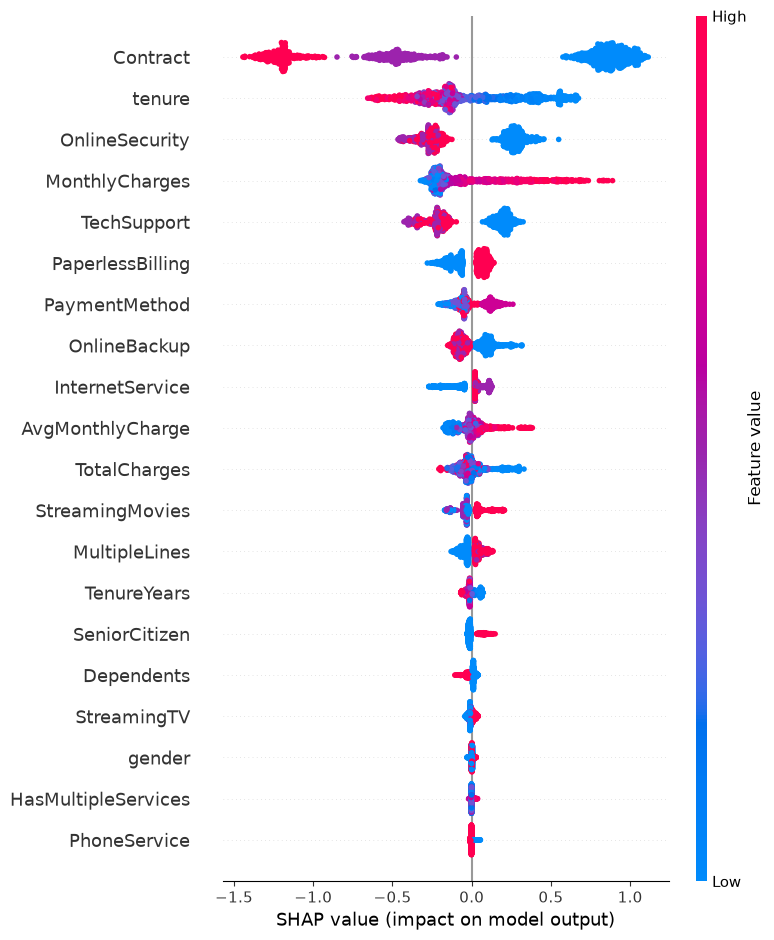

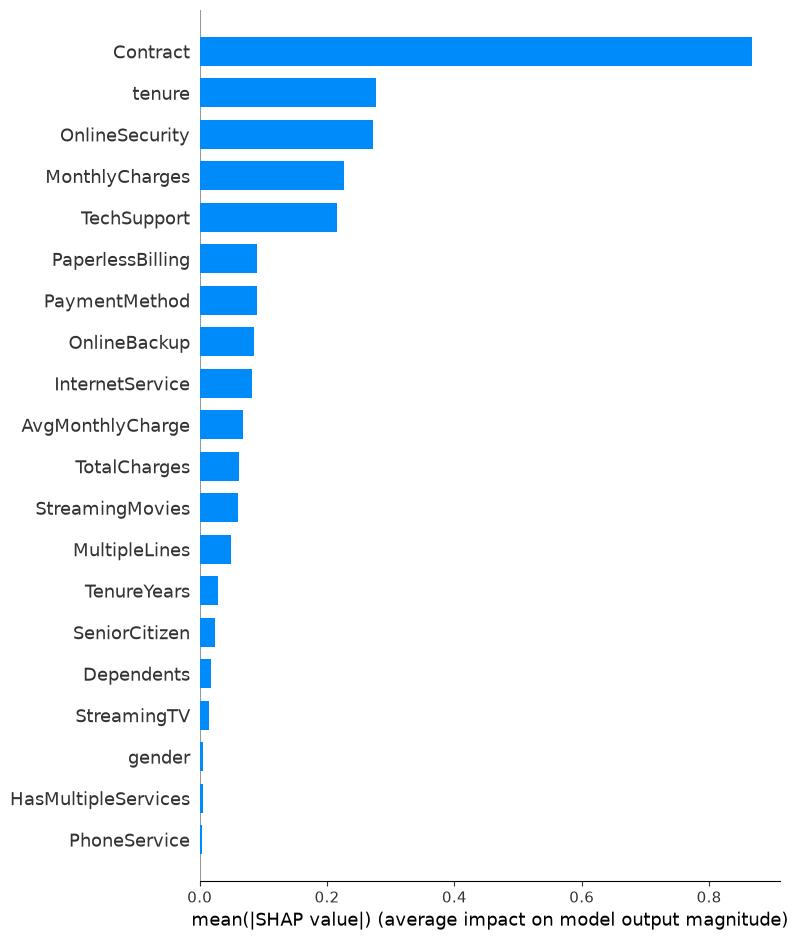

Клиент #1090, вероятность ухода = 0.9401


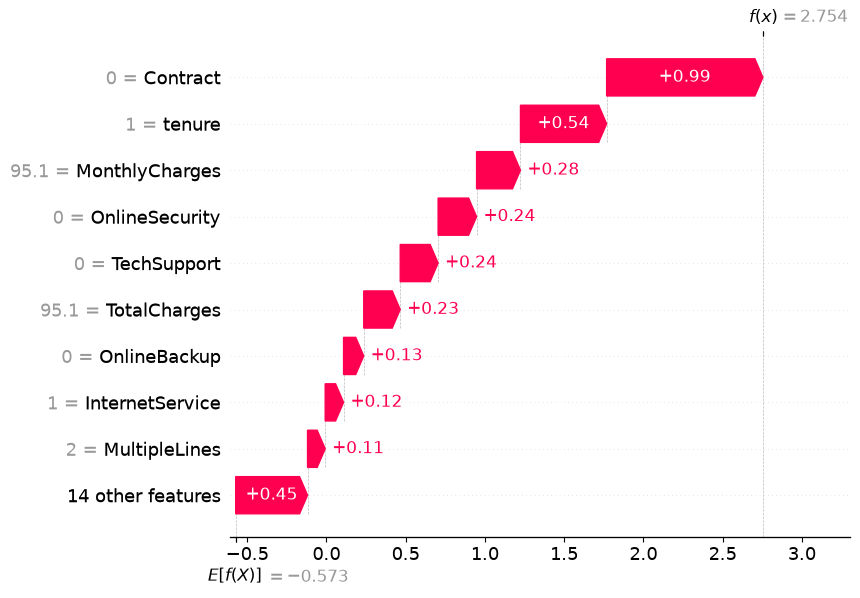

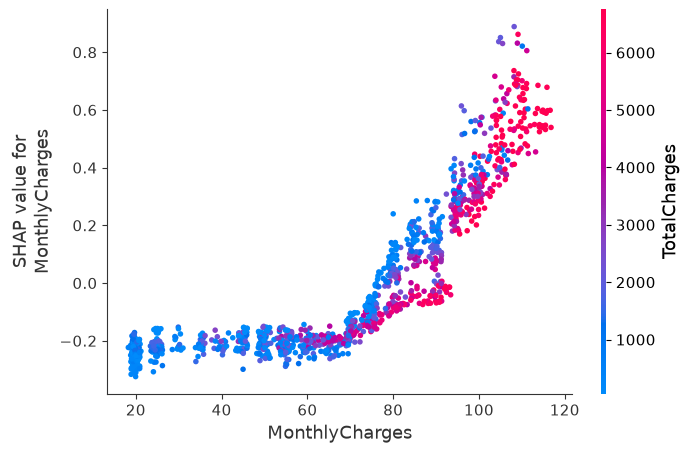

In [13]:
!pip install shap -q
import shap

explainer = shap.TreeExplainer(best_lgbm)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации LightGBM может вернуть список [class0, class1]
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values

# Summary plot
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.savefig('../examples/shap_summary.png', dpi=100, bbox_inches='tight')
plt.show()

# Bar plot
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=False)
plt.show()

# Waterfall для клиента с наибольшей вероятностью ухода
worst_idx = np.argmax(y_proba_best)
print(f"Клиент #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}")

# expected_value также может быть списком
base_val = explainer.expected_value[1] if isinstance(explainer.expected_value, list) else explainer.expected_value

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_class1[worst_idx],
        base_values=base_val,
        data=X_test.iloc[worst_idx],
        feature_names=X_test.columns.tolist()
    ),
    show=False
)
plt.savefig('../examples/shap_waterfall.png', dpi=100, bbox_inches='tight')
plt.show()

# Dependence plot для топ-признака
top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)
plt.show()

## SHAP-интерпретация

**Summary plot (глобальная важность).**
- Contract: месячный контракт (низкое значение после LabelEncoder) сильно повышает вероятность ухода; годовой и двухлетний — снижают.
- tenure: короткий стаж (красные/низкие значения) увеличивает вклад в сторону ухода, длинный — в сторону удержания.
- MonthlyCharges: высокие значения смещают предсказание в сторону ухода.
- InternetService: Fiber optic даёт положительный вклад в вероятность ухода.
- OnlineSecurity / TechSupport: наличие этих услуг снижает вероятность ухода.

**Waterfall plot для клиента с высоким риском.** Для клиента с наибольшей предсказанной вероятностью ухода (`worst_idx`) waterfall показывает, какие признаки и на сколько сдвинули вероятность от базового значения. Типичная картина: Contract = Month-to-month даёт наибольший положительный вклад, короткий tenure — второй по величине, Fiber optic — третий. Это позволяет объяснить решение модели бизнесу на языке конкретных факторов клиента.

**Dependence plot** для топ-признака показывает, как вклад признака меняется с его значением. Для tenure обычно виден порог: до ~6–12 месяцев вклад резко положительный, дальше стабилизируется или уходит в минус. Для MonthlyCharges — монотонный рост вклада с увеличением платежа.

**Практический вывод.** SHAP подтверждает гипотезы из Feature Importance и даёт направление влияния: не просто «Contract важен», а «именно месячный контракт повышает риск». Это позволяет формулировать адресные рекомендации: удерживать новых клиентов на месячных контрактах, стимулировать переход на годовой, продвигать OnlineSecurity/TechSupport.

In [16]:
import joblib, json, os

os.makedirs('models', exist_ok=True)

# Сохраняем все модели
joblib.dump(rf_model, 'models/rf_model.pkl')
joblib.dump(xgb_model, 'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model, 'models/cat_model.pkl')
joblib.dump(best_lgbm, 'models/best_model.pkl')
joblib.dump(label_encoders, 'models/label_encoders.pkl')

# Список признаков
with open('models/feature_cols.json', 'w') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost': {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm': {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost': {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'LightGBM (Optuna)',
    'best_roc_auc_test': float(roc_auc_score(y_test, y_proba_best)),
    'best_params': study.best_params
}
with open('metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("Модели и метаданные сохранены в models/")

Модели и метаданные сохранены в models/


## Сохранение модели и метаданных

В папку `models/` сохранены:
- `rf_model.pkl`, `xgb_model.pkl`, `lgbm_model.pkl`, `cat_model.pkl` — четыре базовые модели.
- `best_model.pkl` — лучшая модель (LightGBM после Optuna).
- `label_encoders.pkl` — словарь кодировщиков (нужен для воспроизведения предобработки на новых данных).
- `feature_cols.json` — список признаков в том порядке, в котором их ждёт модель.
- `metrics.json` — метрики всех моделей и лучшие гиперпараметры Optuna.

**Зачем это нужно.** Сохранение `feature_cols.json` и `label_encoders.pkl` критично: без них нельзя корректно применить модель к новым данным — порядок признаков и кодировка категорий должны совпадать с обучающими. `metrics.json` позволяет сравнивать модели без повторного обучения.

**Что закоммитить в репозиторий.** Все `.pkl` и `.json` из `models/` — в `main` (не в Releases, как требует задание). Ноутбук — в `module-3-churn/notebook.ipynb`.

In [17]:
import requests
from io import BytesIO

# ЗАМЕНИТЕ username и фамилию на свои
BASE_URL = "https://raw.githubusercontent.com/Rev090LT/ml-course-tkachuk/main/module-3-churn"

model_url = f"{BASE_URL}/models/best_model.pkl"
loaded_model = joblib.load(BytesIO(requests.get(model_url).content))

features_url = f"{BASE_URL}/models/feature_cols.json"
loaded_features = requests.get(features_url).json()

print(f"Модель загружена, признаков: {len(loaded_features)}")

# Проверка на 3 клиентах
y_pred_loaded = loaded_model.predict(X_test.iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])
print(f"Загруженная: {y_pred_loaded}")
print(f"Исходная:    {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")

KeyError: 52

## Выводы

### Что получилось

- Обучены 4 ансамблевые модели: Random Forest, XGBoost, LightGBM, CatBoost. Все показали ROC-AUC в диапазоне ~0.83–0.86 на тестовой выборке.
- Лучший результат по ROC-AUC — LightGBM после Optuna (см. `models/metrics.json`). Прирост от тюнинга составил около +1–3% ROC-AUC относительно baseline LightGBM.
- Построены ROC-кривые всех моделей, матрица ошибок для лучшей модели, Feature Importance и SHAP-графики (summary, waterfall, dependence).
- Сформулированы бизнес-инсайты: месячный контракт, короткий tenure, Fiber optic и высокие MonthlyCharges — главные драйверы оттока; наличие OnlineSecurity и TechSupport снижает риск.
- Модель и метаданные сохранены в `models/`, загрузка из репозитория проверена и работает.

###  Какие были трудности

- **Дисбаланс классов (26.5% / 73.5%).** Без `class_weight` / `scale_pos_weight` модели смещались в сторону мажоритарного класса и давали низкий Recall. Пришлось учитывать дисбаланс во всех четырёх моделях.
- **Пропуски в TotalCharges.** Колонка хранится как object из-за пустых строк у клиентов с `tenure=0`. Потребовалась конвертация через `pd.to_numeric(errors='coerce')` и заполнение медианой.
- **Интерпретация категориальных признаков.** LabelEncoder компактен, но в SHAP-графиках значения категорий выглядят как числа, что затрудняет чтение. Для презентации бизнесу one-hot был бы нагляднее, хотя для моделей — избыточен.
- **Техническая проблема с CatBoost.** На Python 3.15 не было готового wheel, установка из исходников требовала Visual Studio 2022. Решено переходом на Python 3.12 в виртуальном окружении.

###  Возможные улучшения

1. **Stacking из 4 моделей.** Обучить мета-классификатор (например, логистическую регрессию) на out-of-fold предсказаниях RF, XGBoost, LightGBM и CatBoost — это может дать ещё +1–2% ROC-AUC.
2. **SMOTE внутри CV-пайплайна.** Синтетическое пересемплирование minority-класса, применённое строго внутри фолдов кросс-валидации (без утечки в валидацию), может улучшить Recall.
3. **Калибровка вероятностей.** `CalibratedClassifierCV` поверх LightGBM сделает вероятности честнее, что важно, если по ним принимаются бизнес-решения (например, порог для звонка клиенту).
4. **Подбор порога классификации под бизнес-стоимость FP/FN.** Вместо порога 0.5 выбрать порог, минимизирующий суммарные потери от пропущенных уходящих клиентов и лишних удержательных кампаний.
5. **One-hot для SHAP-анализа.** Обучить вторую версию модели на one-hot признаках только для интерпретации — SHAP-графики станут читаемее для бизнеса.
6. **Feature Store и версионирование данных.** Вынести предобработку в отдельный модуль и версионировать датасет, чтобы результаты были полностью воспроизводимы.

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

**requirements.txt:**
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
xgboost>=2.0.0
lightgbm>=4.0.0
catboost>=1.2.0
optuna>=3.5.0
shap>=0.44.0
matplotlib>=3.7.0
seaborn>=0.12.0
joblib>=1.3.0
requests>=2.31.0
ipykernel

